# 08b — Request boundaries on the pooled runs (D100)

The participant round records turns, not requests, so D100 fixes a rule that
decides where one request ends and the next begins. This notebook measures
that rule on the **baseline (`1a872c09`) and the regression run (`e097f78e`)
pooled**: 31 cases, 352 executions. In a simulated run the true boundaries are
known, because **one execution is one request**.

**The rule in force (D100): shape + slash, no reference.** For each turn after
the first in a Tonic run:

1. a turn carrying a slash command starts a new request;
2. otherwise a new request starts where the turn's acting shape (`shapes7`,
   D99) changes, and a turn that called nothing joins the request before it.

Reference matching is not part of the rule and is not scored here;
`08_segmentation` and its per-run copies hold that comparison. **Shape only**
is shown beside D100 as the reference point, so the slash signal's own
contribution can be read off.

**Why pooled.** `04_regress` shows the two runs share one configuration: the
same model release, suite and prompts, and no application code change between
their API commits. They are two samples of one system, so executions from
both are fused freely. The per-run copies of `08_segmentation` kept the runs
apart as "two agent builds"; that caution predates the `04_regress` check.
Per-run values stay beside the pooled ones where they are cheap to show.

**What is measured.**

- **Split error**: one request cut in two. Counted inside each execution.
- **Merge error**: two requests read as one. Executions are fused into
  synthetic runs (every ordered pair, and random runs of 3, 5 and 8 requests)
  and the seams the rule misses are counted.
- **Request count**: how many requests the rule reads in a fused run, against
  the true number.

Descriptive only (D104). Figures are written to `figures/segmentation/`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[1]))

import matplotlib.pyplot as plt
import pandas as pd

from src import figures, survey
from src import segmentation_bench as bench
from src.shapes import segment_with

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)

# --- parameters -------------------------------------------------------------
RUN_IDS = {
    "baseline": "1a872c09-7070-4789-a806-904969f9185d",    # B10, adopted (D96)
    "regression": "e097f78e-3326-4aea-acaa-0b904d3b0a1c",  # B11
}
VARIANTS = {"shape only": "shape only", "D100 (shape + slash)": "+ slash"}  # label -> bench variant
RUN_LENGTHS = (3, 5, 8)
RANDOM_RUNS = 2000  # per length; seed 28, as in 08_segmentation
# ---------------------------------------------------------------------------

figures.setup()
save = figures.Saver("segmentation")
pct = "{:.1%}".format

executions, by_run, spanning = {}, {}, []
for name, rid in RUN_IDS.items():
    loaded = survey.turn_signals(rid)
    spanning += loaded.pop(None)
    by_run[name] = {f"{rid[:8]}:{k}": v for k, v in loaded.items()}
    executions.update(by_run[name])
assert not spanning, f"executions spanning more than one Tonic run: {spanning}; the ground truth does not hold"

case_of = lambda key: key.split(":", 1)[1].split("#")[0]
turn_counts = pd.Series({k: len(v) for k, v in executions.items()})
print(f"pooled: {len(executions)} executions of {len({case_of(k) for k in executions})} cases, "
      f"{turn_counts.sum()} turns ({', '.join(f'{n}: {len(v)}' for n, v in by_run.items())} executions)")
print("turns per execution:", turn_counts.value_counts().sort_index().to_dict())
print("executions with a slash command after their first turn:",
      sum(1 for v in executions.values() if any(t.intent for t in v[1:])))

pooled: 352 executions of 31 cases, 426 turns (baseline: 176, regression: 176 executions)
turns per execution: {1: 279, 2: 72, 3: 1}
executions with a slash command after their first turn: 0


## 1. Split error — inside executions

Every execution is one request, so an execution cut into more than one is a
split. Only an execution of more than one turn can split.

In [2]:
within = pd.DataFrame({label: bench.within(executions, v) for label, v in VARIANTS.items()})
multi = turn_counts[turn_counts > 1].index

def split_row(keys):
    w = within.loc[keys]
    return {label: f"{int((w[label] > 1).sum())}/{len(keys)}" for label in VARIANTS}

split = pd.DataFrame({"pooled": split_row(within.index),
                      **{n: split_row(list(v)) for n, v in by_run.items()},
                      "pooled, multi-turn executions only": split_row(multi)}).T
print("executions cut into more than one request:")
split

executions cut into more than one request:


,shape only,D100 (shape + slash)
pooled,35/352,35/352
baseline,19/176,19/176
regression,16/176,16/176
"pooled, multi-turn executions only",35/73,35/73


In [3]:
# Which cases split under D100, and how.
d100 = within["D100 (shape + slash)"]
split_cases = (pd.DataFrame({"case": [case_of(k) for k in within.index], "split": d100 > 1,
                             "turns": turn_counts.reindex(within.index)})
               .groupby("case").agg(executions=("split", "size"), split=("split", "sum"),
                                    turns=("turns", "max")))
split_cases = split_cases[split_cases["split"] > 0].sort_values("split", ascending=False)
split_cases.assign(share=(split_cases["split"] / split_cases["executions"]).map(pct))

,executions,split,turns,share
case,,,,
scheduling_afternoon_then_tram,16,16,2,100.0%
scheduling_dinner_from_offer,16,16,3,100.0%
factual_qa_lisbon_surf_conditions,16,3,2,18.8%


In [4]:
# The shape sequence of every split execution under D100: what the rule saw.
seqs = pd.Series({k: " → ".join(t.label + (f" /{t.intent}" if t.intent else "") for t in executions[k])
                  for k in within.index[d100 > 1]})
pd.DataFrame({"case": [case_of(k) for k in seqs.index], "turn shapes": seqs.values}) \
    .value_counts().rename("executions").to_frame()

,,executions
case,turn shapes,
scheduling_dinner_from_offer,venue.search /find → scheduling.draft,15
scheduling_afternoon_then_tram,scheduling.draft /plan → other,13
factual_qa_lisbon_surf_conditions,other → factual.climate,3
scheduling_afternoon_then_tram,scheduling.draft /plan → scheduling.edit,3
scheduling_dinner_from_offer,venue.search /find → scheduling.draft → advisory,1


## 2. Merge error and request count — fused runs

Recorded executions are concatenated into synthetic Tonic runs whose true
boundaries are known: every ordered pair of executions, then random runs of 3,
5 and 8 requests. For each run the rule's boundaries are compared with the
true ones.

- **boundaries found**: share of true seams the rule draws (1 − merge rate);
- **false boundaries per run**: cuts inside an execution (the split error
  again, now inside fused runs);
- **runs exact**: both right at once;
- **requests read / true**: the request count the rule reports, against the
  true one.

In [5]:
def evaluate(execs, variant, sequences):
    use_intent, use_reference = bench.VARIANTS[variant]
    found = true_total = false_total = exact = read = 0
    for seq in sequences:
        turns, truth = bench.fuse(execs, seq)
        segs = segment_with(turns, use_intent=use_intent, use_reference=use_reference)
        drawn = {s[0] for s in segs} - {0}
        found += len(drawn & truth); true_total += len(truth); false_total += len(drawn - truth)
        exact += drawn == truth; read += len(segs)
    n = len(sequences)
    return {"runs": n, "boundaries found": found / true_total, "false boundaries per run": false_total / n,
            "runs exact": exact / n, "requests read / true": read / sum(len(s) for s in sequences)}

samples = {"all pairs": bench.all_pairs(executions)}
samples.update({f"runs of {k}": bench.random_runs(executions, k, RANDOM_RUNS) for k in RUN_LENGTHS})

fused = pd.DataFrame([{"sample": s, "variant": label, **evaluate(executions, v, seqs)}
                      for s, seqs in samples.items() for label, v in VARIANTS.items()])
print(f"ordered pairs: {len(samples['all pairs']):,}; random runs: {RANDOM_RUNS:,} per length")
fused.set_index(["sample", "variant"]).style.format(
    {"runs": "{:,.0f}", "boundaries found": "{:.1%}", "false boundaries per run": "{:.3f}",
     "runs exact": "{:.1%}", "requests read / true": "{:.3f}"})

ordered pairs: 123,552; random runs: 2,000 per length


In [6]:
# The headline per run, for the pairs only: pooled pairs mix both runs, per-run pairs stay inside one.
per_run = {}
for name, execs in {"pooled": executions, **by_run}.items():
    r = evaluate(execs, "+ slash", bench.all_pairs(execs))
    per_run[name] = {"executions": len(execs), "ordered pairs": f"{r['runs']:,}",
                     "boundaries found": pct(r["boundaries found"]),
                     "false boundaries per pair": f"{r['false boundaries per run']:.3f}",
                     "pairs exact": pct(r["runs exact"])}
print("D100, all ordered pairs:")
pd.DataFrame(per_run)

D100, all ordered pairs:


,pooled,baseline,regression
executions,352,176,176
ordered pairs,"123,552","30,800","30,800"
boundaries found,92.0%,92.3%,91.9%
false boundaries per pair,0.199,0.216,0.182
pairs exact,73.4%,72.4%,74.6%


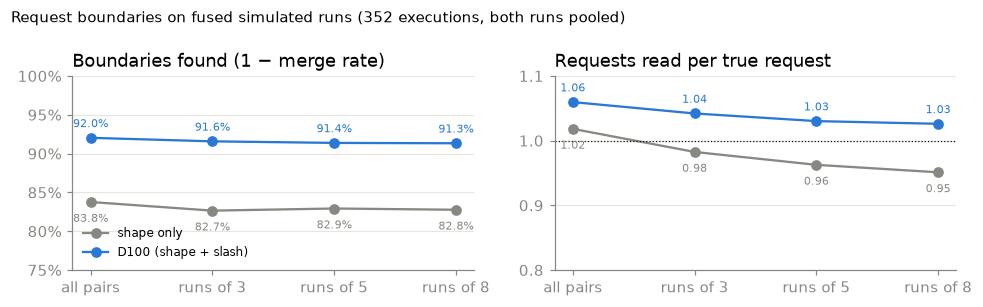

In [7]:
# Figure S1 — boundaries found and requests read per run length, both variants.
order = list(samples)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8))
colors = {"shape only": figures.MUTED, "D100 (shape + slash)": figures.SERIES}
for ax, col, title, fmt in ((axs[0], "boundaries found", "Boundaries found (1 − merge rate)", "{:.1%}"),
                            (axs[1], "requests read / true", "Requests read per true request", "{:.2f}")):
    for label in VARIANTS:
        vals = fused[fused["variant"] == label].set_index("sample").loc[order, col]
        ax.plot(range(len(order)), vals, "o-", color=colors[label], label=label, markersize=6)
        for x, v in enumerate(vals):
            ax.annotate(fmt.format(v), (x, v), xytext=(0, 7 if label.startswith("D100") else -13),
                        textcoords="offset points",
                        ha="center", fontsize=7, color=colors[label])
    ax.set_xticks(range(len(order)), order); ax.set_title(title)
    ax.grid(axis="y", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
axs[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axs[0].set_ylim(0.75, 1.0)
axs[1].axhline(1, color=figures.INK, linewidth=0.8, linestyle=":")
axs[1].set_ylim(0.8, 1.1)
axs[0].legend(frameon=False, loc="lower left", fontsize=8)
fig.suptitle(f"Request boundaries on fused simulated runs ({len(executions)} executions, both runs pooled)",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout(); save(fig, "S1_boundaries_by_run_length"); plt.show()

## 3. Where seams are missed

Without reference, D100 can only miss a seam where the next request **opens
with the same shape as the request before it ended, and without a command**.
Over all ordered pairs, the miss rate by the shape the second request opens
with shows which kinds of request would be read as one in the participant
round.

**Read this with the slash share in mind.** In the suite every search and
scheduling seed opens with a command (`/find`, `/plan`, `/reschedule`), so
those requests never merge here, and the misses all fall on factual and mixed
requests, which open without one. Participants may type commands less often.
With no commands at all, D100 is shape only: the grey line in S1, about 83 %
of boundaries found instead of about 92 %. The two lines bound what the
participant round can expect.

In [8]:
rows = []
use_intent, use_reference = bench.VARIANTS["+ slash"]
for a, b in samples["all pairs"]:
    turns, truth = bench.fuse(executions, (a, b))
    drawn = {s[0] for s in segment_with(turns, use_intent=use_intent, use_reference=use_reference)} - {0}
    rows.append({"opens with": executions[b][0].label, "slash": bool(executions[b][0].intent),
                 "missed": not (truth <= drawn)})
seams = pd.DataFrame(rows)
miss = seams.groupby("opens with").agg(pairs=("missed", "size"), missed=("missed", "sum"),
                                       **{"opens with a slash": ("slash", "mean")})
miss["miss rate"] = miss["missed"] / miss["pairs"]
miss = miss.sort_values("miss rate", ascending=False)
print(f"seams missed under D100: {int(seams['missed'].sum()):,} of {len(seams):,} = {pct(seams['missed'].mean())}")
print(f"  second request opens with a slash command: {pct(seams['slash'].mean())} of pairs, "
      f"missed {int(seams.loc[seams['slash'], 'missed'].sum())}")
miss.style.format({"pairs": "{:,}", "missed": "{:,}", "miss rate": "{:.1%}", "opens with a slash": "{:.0%}"})

seams missed under D100: 9,846 of 123,552 = 8.0%
  second request opens with a slash command: 50.0% of pairs, missed 0


,pairs,missed,opens with a slash,miss rate
opens with,,,,
factual.climate,"23,517","4,623",0%,19.7%
factual.reference,"22,113","3,906",0%,17.7%
factual.forecast,"11,232",992,0%,8.8%
other,"4,914",325,0%,6.6%
scheduling.draft,"16,848",0,100%,0.0%
scheduling.edit,"14,040",0,100%,0.0%
venue.search,"30,888",0,100%,0.0%


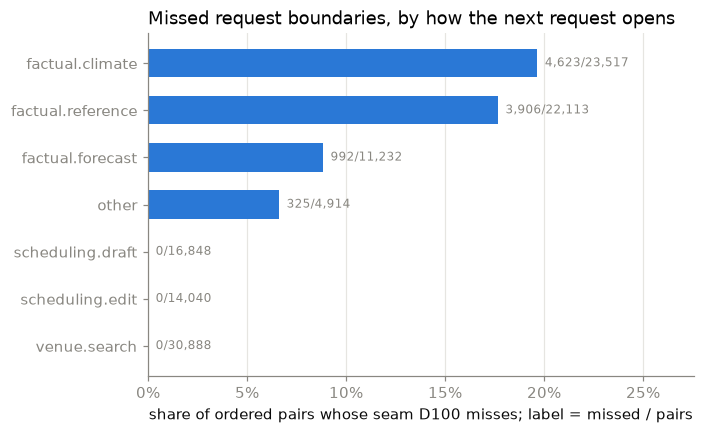

In [9]:
# Figure S2 — share of seams D100 misses, by the shape the next request opens with.
fig, ax = plt.subplots(figsize=(6.4, 0.42 * len(miss) + 1.1))
ys = range(len(miss))[::-1]
ax.barh(list(ys), miss["miss rate"], color=figures.SERIES, height=0.6)
for y, (shape, r) in zip(ys, miss.iterrows()):
    ax.annotate(f"{int(r['missed']):,}/{int(r['pairs']):,}", (r["miss rate"], y), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=8, color=figures.MUTED)
ax.set_yticks(list(ys), miss.index)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, min(1, miss["miss rate"].max() * 1.3 + 0.02))
ax.set_xlabel("share of ordered pairs whose seam D100 misses; label = missed / pairs")
ax.grid(axis="x", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Missed request boundaries, by how the next request opens")
save(fig, "S2_missed_by_shape"); plt.show()

## 4. Numbers for the report

Printed from the tables above, so the text quotes what was computed.

In [10]:
pairs = fused.set_index(["sample", "variant"])
d, s0 = pairs.loc[("all pairs", "D100 (shape + slash)")], pairs.loc[("all pairs", "shape only")]
k8 = pairs.loc[("runs of 8", "D100 (shape + slash)")]
n_split = int((d100 > 1).sum())
print(f"Pooled runs: {len(executions)} executions of 31 cases, {turn_counts.sum()} turns, "
      f"{len(multi)} with more than one turn.")
print(f"Split: D100 cuts {n_split} of {len(executions)} executions ({pct(n_split / len(executions))}) in two or more, "
      f"{n_split} of {len(multi)} multi-turn executions ({pct(n_split / len(multi))}).")
print(f"Merge: over {int(d['runs']):,} ordered pairs, D100 finds {pct(d['boundaries found'])} of boundaries "
      f"(shape only {pct(s0['boundaries found'])}); {pct(d['runs exact'])} of pairs are segmented exactly.")
print(f"Runs of 8 requests: boundaries found {pct(k8['boundaries found'])}, "
      f"{k8['false boundaries per run']:.2f} false boundaries per run, requests read / true "
      f"{k8['requests read / true']:.3f}.")
print(f"Figures written to {save.dir.resolve()}")

Pooled runs: 352 executions of 31 cases, 426 turns, 73 with more than one turn.
Split: D100 cuts 35 of 352 executions (9.9%) in two or more, 35 of 73 multi-turn executions (47.9%).
Merge: over 123,552 ordered pairs, D100 finds 92.0% of boundaries (shape only 83.8%); 73.4% of pairs are segmented exactly.
Runs of 8 requests: boundaries found 91.3%, 0.81 false boundaries per run, requests read / true 1.026.
Figures written to C:\Users\gian-\Documents\GitHub\trip_tonic\research\regression-testing\notebooks\sim\figures\segmentation
